<a href="https://colab.research.google.com/github/Amadi200/montra_hospitality/blob/main/05_topic_sentiment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Install required packages

In [1]:
!pip install -q transformers torch pandas pyarrow matplotlib seaborn tqdm

Imports

In [2]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

from transformers import pipeline
import torch

pd.set_option("display.max_colwidth", 140)
pd.set_option("display.max_columns", 50)

Load your data

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
DATA_PATH = "/content/drive/MyDrive/Montra_Hospitality/outputs/bertopic/reviews_with_topics.parquet"

df = pd.read_parquet(DATA_PATH)
print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
display(df.head(3))

Shape: (34536, 29)

Columns: ['review_id', 'booking_id', 'guest_id', 'hotel_id', 'review_text', 'rating_score', 'review_date', 'sentiment_label', 'bk_guest_id', 'bk_hotel_id', 'bk_room_type', 'bk_booking_channel', 'bk_check_in_date', 'bk_check_out_date', 'bk_total_amount', 'bk_stay_duration', 'gt_customer_type', 'gt_loyalty_status', 'gt_country', 'gt_previous_stays', 'ht_hotel_name', 'ht_location', 'ht_star_rating', 'ht_total_rooms', 'review_text_ml', 'text_length', 'word_count', 'topic', 'topic_probability']


,review_id,booking_id,guest_id,hotel_id,review_text,rating_score,review_date,sentiment_label,bk_guest_id,bk_hotel_id,bk_room_type,bk_booking_channel,bk_check_in_date,bk_check_out_date,bk_total_amount,bk_stay_duration,gt_customer_type,gt_loyalty_status,gt_country,gt_previous_stays,ht_hotel_name,ht_location,ht_star_rating,ht_total_rooms,review_text_ml,text_length,word_count,topic,topic_probability
0,1,1,6699,18,"The overall price was fair for what we paid. Might consider it again, might not.",3.2,2025-06-02,NaT,6699,18,Suite,Direct Website,2025-05-25,2025-05-26,296.44,1,Leisure,None,France,4,The Aberdeen Grand,Aberdeen,4,118,the overall price was fair for what we paid might consider it again might not,80,15,2,1.0
1,2,2,11380,23,"The room was nothing out of the ordinary for what we paid. The overall price exceeded our expectations — a great deal, and the quality e...",4.0,2025-01-22,NaT,11380,23,Deluxe,Corporate Portal,2025-01-09,2025-01-13,483.56,4,Business,Gold,Germany,4,Nottingham Park Hotel,Nottingham,4,95,the room was nothing out of the ordinary for what we paid the overall price exceeded our expectations a great deal and the quality easil...,158,28,10,1.0
2,3,3,4812,13,"Unfortunately, the pool was outdated — it clearly needed some upkeep. Wouldn't recommend it to others.",1.9,2025-03-13,NaT,4812,13,Executive,Travel Agent,2025-03-04,2025-03-06,415.59,2,Business,None,Ireland,4,The London Boutique,London,4,231,unfortunately the pool was outdated it clearly needed some upkeep wouldn't recommend it to others,100,15,0,1.0


Basic checks

In [5]:

if "review_text" not in df.columns:
    raise ValueError("Column 'review_text' not found.")

if "topic" not in df.columns:
    raise ValueError("Column 'topic' not found.")

print(f"\nTotal topics (including -1): {df['topic'].nunique()}")
print(f"Outlier reviews (topic = -1): {(df['topic'] == -1).sum():,}")


Total topics (including -1): 43
Outlier reviews (topic = -1): 4,406


Load Sentiment Model

In [6]:
device = 0 if torch.cuda.is_available() else -1
print("\nUsing:", "GPU" if device == 0 else "CPU")

sentiment_pipe = pipeline(
    "sentiment-analysis",
    model="cardiffnlp/twitter-roberta-base-sentiment-latest",
    tokenizer="cardiffnlp/twitter-roberta-base-sentiment-latest",
    device=device,
    truncation=True,
    max_length=512
)

label_map = {
    "negative": "Negative",
    "neutral": "Neutral",
    "positive": "Positive"
}


Using: GPU


config.json:   0%|          | 0.00/929 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  501MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

...

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  501MB            

model.safetensors: downloading bytes:           |  0.00B            

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Predict Sentiment

In [7]:
print("\nPredicting sentiment on all reviews... (this may take several minutes)")

def predict_sentiment(text):
    try:
        result = sentiment_pipe(str(text)[:1000])[0]
        label = label_map.get(result["label"].lower(), result["label"])
        score = round(result["score"], 4)
        return pd.Series([label, score])
    except:
        return pd.Series(["Neutral", 0.0])

tqdm.pandas()
df[["sentiment", "sentiment_score"]] = df["review_text"].progress_apply(predict_sentiment)

print("\nOverall Sentiment Distribution:")
print(df["sentiment"].value_counts())


Predicting sentiment on all reviews... (this may take several minutes)


  0%|          | 0/34536 [00:00<?, ?it/s]

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset



Overall Sentiment Distribution:
sentiment
Positive    21491
Negative    10120
Neutral      2925
Name: count, dtype: int64


Topic-Level Sentiment Summary

In [8]:
topic_sentiment = (
    df.groupby("topic")
    .agg(
        review_count        = ("review_text", "count"),
        positive_count      = ("sentiment", lambda x: (x == "Positive").sum()),
        neutral_count       = ("sentiment", lambda x: (x == "Neutral").sum()),
        negative_count      = ("sentiment", lambda x: (x == "Negative").sum()),
        avg_sentiment_score = ("sentiment_score", "mean")
    )
    .reset_index()
)

# Percentages
topic_sentiment["positive_pct"] = (topic_sentiment["positive_count"] / topic_sentiment["review_count"] * 100).round(1)
topic_sentiment["neutral_pct"]  = (topic_sentiment["neutral_count"]  / topic_sentiment["review_count"] * 100).round(1)
topic_sentiment["negative_pct"] = (topic_sentiment["negative_count"] / topic_sentiment["review_count"] * 100).round(1)

# Dominant sentiment
topic_sentiment["dominant_sentiment"] = (
    topic_sentiment[["positive_pct", "neutral_pct", "negative_pct"]]
    .idxmax(axis=1)
    .str.replace("_pct", "")
    .str.capitalize()
)

topic_sentiment = topic_sentiment.sort_values("review_count", ascending=False)

print("\n===== Topic Sentiment Summary =====")
display(topic_sentiment)


===== Topic Sentiment Summary =====


,topic,review_count,positive_count,neutral_count,negative_count,avg_sentiment_score,positive_pct,neutral_pct,negative_pct,dominant_sentiment
1,0,17834,11143,1473,5218,0.844950,62.5,8.3,29.3,Positive
0,-1,4406,2552,324,1530,0.862610,57.9,7.4,34.7,Positive
2,1,1098,694,75,329,0.835349,63.2,6.8,30.0,Positive
3,2,1064,562,163,339,0.797579,52.8,15.3,31.9,Positive
4,3,803,521,49,233,0.847607,64.9,6.1,29.0,Positive
5,4,775,515,44,216,0.849631,66.5,5.7,27.9,Positive
6,5,729,478,45,206,0.860134,65.6,6.2,28.3,Positive
7,6,667,421,49,197,0.833505,63.1,7.3,29.5,Positive
8,7,568,395,21,152,0.848305,69.5,3.7,26.8,Positive
9,8,514,297,148,69,0.770559,57.8,28.8,13.4,Positive


Visualizations

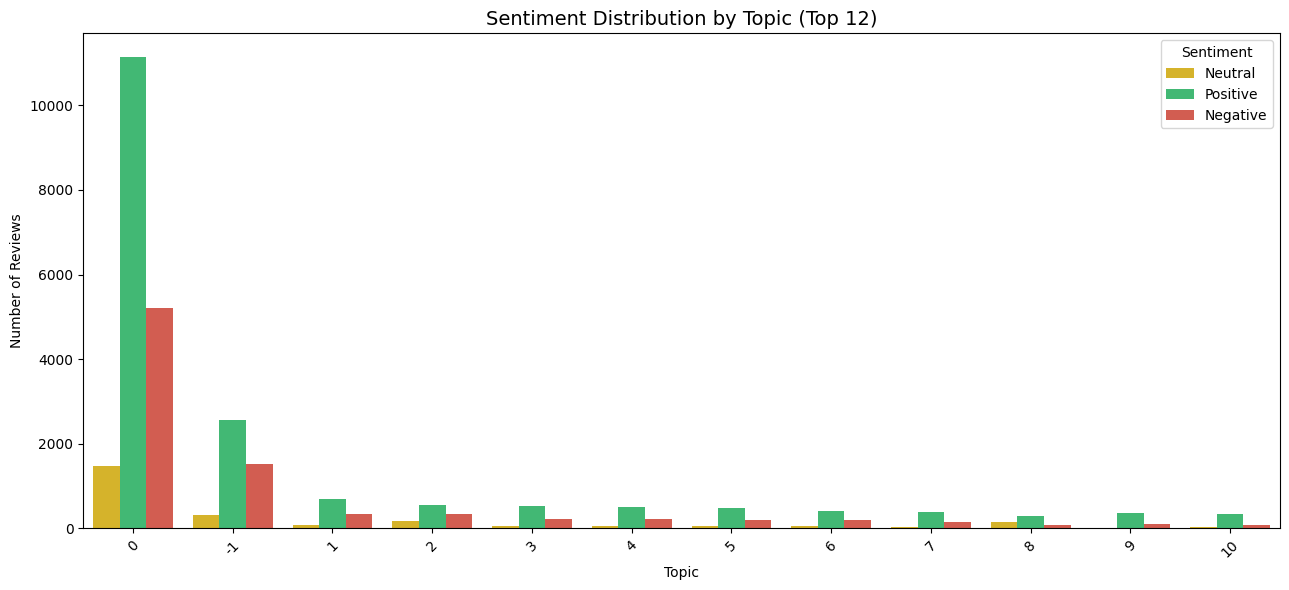

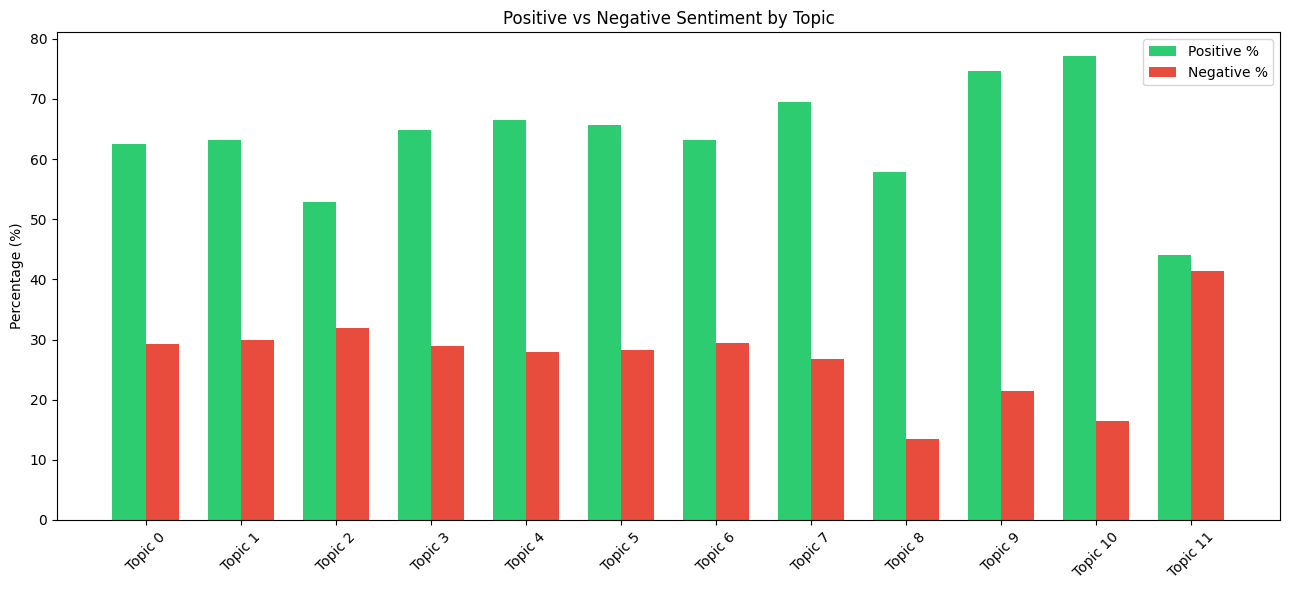

In [9]:
# 8.1 Sentiment distribution by top topics
top_n = 12
top_topics = topic_sentiment.head(top_n)["topic"].tolist()

plot_df = df[df["topic"].isin(top_topics)].copy()
plot_df["topic"] = plot_df["topic"].astype(str)

plt.figure(figsize=(13, 6))
sns.countplot(
    data=plot_df,
    x="topic",
    hue="sentiment",
    order=[str(t) for t in top_topics],
    palette={"Positive": "#2ecc71", "Neutral": "#f1c40f", "Negative": "#e74c3c"}
)
plt.title(f"Sentiment Distribution by Topic (Top {top_n})", fontsize=14)
plt.xlabel("Topic")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=45)
plt.legend(title="Sentiment")
plt.tight_layout()
plt.show()

# 8.2 Positive vs Negative percentage
plot_data = topic_sentiment[topic_sentiment["topic"] != -1].head(top_n)

x = np.arange(len(plot_data))
width = 0.35

plt.figure(figsize=(13, 6))
plt.bar(x - width/2, plot_data["positive_pct"], width, label="Positive %", color="#2ecc71")
plt.bar(x + width/2, plot_data["negative_pct"], width, label="Negative %", color="#e74c3c")

plt.xticks(x, [f"Topic {int(t)}" for t in plot_data["topic"]], rotation=45)
plt.ylabel("Percentage (%)")
plt.title("Positive vs Negative Sentiment by Topic")
plt.legend()
plt.tight_layout()
plt.show()

Save Results to Google Drive

In [10]:
output_dir = Path("/content/drive/MyDrive/Montra_Hospitality/outputs/topic_sentiment")
output_dir.mkdir(parents=True, exist_ok=True)

# Save full data with sentiment
df.to_parquet(output_dir / "reviews_with_topic_sentiment.parquet", index=False)

# Save summary table
topic_sentiment.to_csv(output_dir / "topic_sentiment_summary.csv", index=False)

print(f"\nResults successfully saved to:")
print(output_dir)
print(" - reviews_with_topic_sentiment.parquet")
print(" - topic_sentiment_summary.csv")


Results successfully saved to:
/content/drive/MyDrive/Montra_Hospitality/outputs/topic_sentiment
 - reviews_with_topic_sentiment.parquet
 - topic_sentiment_summary.csv
